In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import glob
import pickle
import threading
import traceback
from concurrent.futures import ThreadPoolExecutor, as_completed
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.layers import ELU1
from digitalbat.training.trainer import bat_former_trainer, finetune_readout_trainer
from digitalbat.utility.utils import set_random_state, poisson_fde_population, corr


In [2]:
SEED = 1
WD_GRID = [0.01, 0.1]
WD_SCRATCH_GRID = [0.01, 0.1, 1.0]
DEVICE = 'cuda'

# Training budget (see plan: user chose smoke-test sizing)
N_EPOCHS_FOUNDATION = 1000
N_EPOCHS_FINETUNE = 1000
N_EPOCHS_SCRATCH = 1000
EARLY_STOP_PATIENCE = 100
LR = 1e-2

# Parallel-within-GPU training. Tune based on `nvidia-smi` VRAM headroom.
MAX_WORKERS = 32

OUT_ROOT = os.path.abspath('./out/transfer')
os.makedirs(OUT_ROOT, exist_ok=True)

set_random_state(SEED)

# Dataloader (all 18 sessions)

In [3]:
data_config = dict(
    use_speed_head_dir = False,
    use_IMU_flag = False,
    use_click_flag = False,
    use_LFP_flag = False,
    use_ripple_flag = False,
    only_flight_flag = True,
    firing_rate_criterion_flag = True,
    max_acceleration = 50,
    no_3d_location = False,
    spike_count_flag = True,
    bin_width = 0.10,
    split_flights_for_train = 'random',
    type_train_num = 1,
    type_valid_num = 1,
    special_id_count_thresh = 3,
    only_use_special_id_4train_flag = False,
    shuffle_flag = True,
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False,
    split_each_trajectory_flag = True,
    window_size = None,
    stride_train = None,
    stride_test = None,
    batch_size_train = None,
    batch_size_test = None,
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209',
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',
        'Dataset_1_32622_231007',
        'Dataset_2_14611_231208',
        'Dataset_2_14611_231209',
        'Dataset_3_00000_240402',
        'Dataset_3_00000_240403',
        'Dataset_3_00000_240404',
        'Dataset_3_00000_240405',
        'Dataset_3_29959_240405',
    ],
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'Loaded {len(unit_num_dict)} sessions, behavior_dim={behavior_dim}')
print(f'Units per session: {unit_num_dict}')

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
Loaded 18 sessions, behavior_dim=3
Units per session: {'Dataset_3_14543_240419': 204, 'Dataset_3_14543_240420': 77, 'Dataset_3_14543_240421': 65, 'Dataset_3_29959_240402': 266, 'Dataset_3_29959_240403': 149, 'Dataset_3_29959_240404': 121, 'Dataset_2_14445_231208': 155, 'Dataset_2_14445_231209': 102, 'Dataset_1_32622_231009':

# Experiment bookkeeping

In [4]:
SESSIONS = list(unit_num_dict)

def dataset_of(session_name):
    # 'Dataset_{N}_...' -> 'D{N}'
    return 'D' + session_name.split('_')[1]

def bat_of(session_name):
    # 'Dataset_{N}_{bat_id}_{date}'
    return session_name.split('_')[2]

SESSIONS_D13 = [s for s in SESSIONS if dataset_of(s) != 'D2']
SESSIONS_D2  = [s for s in SESSIONS if dataset_of(s) == 'D2']

BATS = sorted({bat_of(s) for s in SESSIONS})
BATS_D13 = sorted({bat_of(s) for s in SESSIONS_D13})

print(f'All sessions ({len(SESSIONS)}): {SESSIONS}')
print(f'D1+D3 sessions ({len(SESSIONS_D13)}): {SESSIONS_D13}')
print(f'D2 sessions ({len(SESSIONS_D2)}): {SESSIONS_D2}')
print(f'Bats ({len(BATS)}): {BATS}')
print(f'Bats D1+D3 ({len(BATS_D13)}): {BATS_D13}')

All sessions (18): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D1+D3 sessions (14): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D2 sessions (4): ['Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209']
Bats

# Helpers

In [5]:
def filter_dataloaders(dataloaders, keep_sessions):
    """Return a new train/valid/test dict restricted to `keep_sessions` (preserving order)."""
    keep = list(keep_sessions)
    return {
        split: {s: dataloaders[split][s] for s in keep if s in dataloaders[split]}
        for split in ('train', 'valid', 'test')
    }


MODEL_CONFIG_BASE = dict(
    use_place_as_input=False,
    use_trajectory_as_input=True,
    latent_dim=32,
    ff_dim=32,
    num_heads=4,
    num_layers=1,
    dropout_prob=0.3,
    final_activation=ELU1(),
)

def build_bat_former(unit_num_sub, behavior_dim, seed=SEED):
    """Fresh Bat_Transformer with readouts sized for sessions in `unit_num_sub`."""
    set_random_state(seed)
    return Bat_Transformer(
        input_dim=behavior_dim,
        output_dim_dict=unit_num_sub,
        **MODEL_CONFIG_BASE,
    )


def freeze_core_for_finetune(model, target_session):
    """Freeze transformer core and all non-target readouts; keep readouts[target_session] trainable."""
    for p in model.parameters():
        p.requires_grad = False
    for p in model.readouts[target_session].parameters():
        p.requires_grad = True
    # sanity check
    n_train = sum(p.requires_grad for p in model.parameters())
    n_target = sum(p.requires_grad for p in model.readouts[target_session].parameters())
    assert n_train == n_target, f'freeze mismatch: {n_train} != {n_target}'
    return model

In [6]:
def ckpt_path(group, heldout, suffix=''):
    """./out/transfer/{group}/bat_former_seed_{SEED}_wd_sweep_by_{group}_held_{heldout}{suffix}.pth

    The literal `wd_sweep` token replaces the previous fixed-WD value: each model now picks
    its own WD from WD_GRID by validation score. The canonical save_path holds the chosen
    best; per-WD checkpoints from the sweep live alongside at `wd_path(save_path, wd)`.
    """
    d = os.path.join(OUT_ROOT, group)
    os.makedirs(d, exist_ok=True)
    name = f'bat_former_seed_{SEED}_wd_sweep_by_{group}_held_{heldout}{suffix}.pth'
    return os.path.join(d, name)


def wd_path(save_path, wd):
    """Per-WD checkpoint path used during the sweep; the canonical save_path holds the best."""
    base, ext = os.path.splitext(save_path)
    return f'{base}__wd{wd}{ext}'


def eval_on_session(model, session, dataloaders, split='test'):
    """Return per-neuron FDE and mean corr on the given session/split."""
    model = model.to(DEVICE)
    model.eval()
    y_true_list, y_pred_list = [], []
    with torch.no_grad():
        for batch in dataloaders[split][session]:
            X = batch.behavior.to(DEVICE)
            mask = batch.mask.to(DEVICE)
            y = batch.spike.to(DEVICE)
            y_pred = model(session, X, mask)
            y_true_list.append(y.detach()[mask == 1.0].cpu().numpy())
            y_pred_list.append(y_pred.detach()[mask == 1.0].cpu().numpy())
    y_true = np.vstack(y_true_list)
    y_pred = np.vstack(y_pred_list)
    fde = poisson_fde_population(y_true, y_pred)
    pc = corr(y_true, y_pred, axis=0)
    return fde, pc

# Parallel-within-GPU runner

A ThreadPoolExecutor shares one CUDA context; distinct `nn.Module` instances don't race on each other's parameters. We give each worker its own `torch.cuda.Stream` so kernels interleave instead of serializing on the default stream. If VRAM is tight, lower `MAX_WORKERS`: tasks that OOM get retried serially at the end.

In [7]:
def _run_on_stream(fn):
    stream = torch.cuda.Stream()
    with torch.cuda.stream(stream):
        out = fn()
    stream.synchronize()
    return out


def run_tasks_parallel(tasks, max_workers=MAX_WORKERS, label=''):
    """
    tasks: list of (task_id, callable_no_args) tuples.
    Returns: {task_id: result}. OOM failures are retried serially after the parallel wave.
    """
    results = {}
    oom_retries = []

    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futs = {pool.submit(_run_on_stream, fn): tid for tid, fn in tasks}
        for fut in as_completed(futs):
            tid = futs[fut]
            try:
                results[tid] = fut.result()
                print(f'[{label}] done: {tid}')
            except torch.cuda.OutOfMemoryError:
                print(f'[{label}] OOM on {tid}, will retry serially')
                oom_retries.append(tid)
            except Exception as e:
                print(f'[{label}] {tid} FAILED: {type(e).__name__}: {e}')
                traceback.print_exc()
                results[tid] = None

    if oom_retries:
        torch.cuda.empty_cache()
        tid_to_fn = dict(tasks)
        for tid in oom_retries:
            try:
                print(f'[{label}] serial retry: {tid}')
                results[tid] = tid_to_fn[tid]()
            except Exception as e:
                print(f'[{label}] {tid} FAILED (serial): {e}')
                results[tid] = None
    return results

# Single-fold training primitives

In [8]:
def _sweep_wd_train(build_fn, dl_sub, save_path, n_epochs,
                     target_session=None, wd_grid=WD_GRID):
    """
    For each WD in `wd_grid`, train a fresh model (via `build_fn()`) and save its checkpoint
    to `wd_path(save_path, wd)`. After the sweep, copy the best-by-validation checkpoint to
    the canonical `save_path` and return (best_score, best_model, best_wd).

    `target_session` is None for foundation/scratch (uses bat_former_trainer) and set for
    finetune (uses finetune_readout_trainer).
    """
    finetune = target_session is not None
    sweep_results = []  # (score, wd, sweep_path)
    for wd in wd_grid:
        sweep_save = wd_path(save_path, wd)
        model = build_fn()
        cfg = dict(
            model=model, dataloaders=dl_sub, device=DEVICE,
            n_epochs=n_epochs, lr=LR, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=EARLY_STOP_PATIENCE,
            save_model=True, model_name=sweep_save,
        )
        if finetune:
            cfg['target_session'] = target_session
            score, _, _ = finetune_readout_trainer(**cfg)
        else:
            score, _, _ = bat_former_trainer(**cfg)
        sweep_results.append((float(score), wd, sweep_save))
        del model
        torch.cuda.empty_cache()

    best_score, best_wd, best_sweep_path = max(sweep_results, key=lambda x: x[0])
    final_model = build_fn()
    final_model.load_state_dict(torch.load(best_sweep_path, map_location=DEVICE))
    final_model.to(DEVICE)
    torch.save(final_model.state_dict(), save_path)
    print(f'  [sweep] {os.path.basename(save_path)}  best_wd={best_wd}  '
          f'val={best_score:.4f}  (sweep: '
          + ', '.join(f'wd={wd}->{s:.4f}' for s, wd, _ in sweep_results) + ')')
    return best_score, final_model, best_wd


def train_foundation(source_sessions, save_path, seed=SEED, wd_grid=WD_GRID):
    """Train Bat_Transformer on `source_sessions` over a WD sweep; save best to save_path."""
    unit_sub = {s: unit_num_dict[s] for s in source_sessions}
    dl_sub = filter_dataloaders(dataloaders, source_sessions)
    def build():
        return build_bat_former(unit_sub, behavior_dim, seed=seed)
    best_score, model, _ = _sweep_wd_train(build, dl_sub, save_path,
                                             n_epochs=N_EPOCHS_FOUNDATION,
                                             wd_grid=wd_grid)
    return best_score, model


def train_scratch(target_session, save_path, seed=SEED, wd_grid=WD_GRID):
    """Train Bat_Transformer from scratch on a single target session over a WD sweep."""
    unit_sub = {target_session: unit_num_dict[target_session]}
    dl_sub = filter_dataloaders(dataloaders, [target_session])
    def build():
        return build_bat_former(unit_sub, behavior_dim, seed=seed)
    best_score, model, _ = _sweep_wd_train(build, dl_sub, save_path,
                                             n_epochs=N_EPOCHS_SCRATCH,
                                             wd_grid=wd_grid)
    return best_score, model


def finetune_from(foundation_path, source_sessions, target_session, save_path,
                   seed=SEED, wd_grid=WD_SCRATCH_GRID):
    """
    Sweep WD for the target readout: load foundation weights once (the canonical
    save_path of the foundation already reflects its own WD-sweep winner), freeze the core,
    and fine-tune only the new readout for `target_session` at each WD in the grid.
    """
    all_sessions = list(source_sessions) + [target_session]
    unit_sub = {s: unit_num_dict[s] for s in all_sessions}
    dl_sub = filter_dataloaders(dataloaders, [target_session])
    state = torch.load(foundation_path, map_location=DEVICE)
    target_prefix = f'readouts.{target_session}.'

    def build():
        model = build_bat_former(unit_sub, behavior_dim, seed=seed)
        filtered = {k: v for k, v in state.items() if not k.startswith(target_prefix)}
        msg = model.load_state_dict(filtered, strict=False)
        unexpected = list(msg.unexpected_keys)
        target_missing = [k for k in msg.missing_keys if k.startswith(target_prefix)]
        other_missing = [k for k in msg.missing_keys if not k.startswith(target_prefix)]
        assert not unexpected, f'unexpected keys: {unexpected}'
        assert not other_missing, f'unexpected missing keys: {other_missing}'
        assert target_missing, 'expected target readout to be fresh'
        freeze_core_for_finetune(model, target_session)
        return model

    best_score, model, _ = _sweep_wd_train(build, dl_sub, save_path,
                                             n_epochs=N_EPOCHS_FINETUNE,
                                             target_session=target_session,
                                             wd_grid=wd_grid)
    return best_score, model

In [9]:
def _record_eval(rows, model, target_session, group, heldout, mode):
    fde, pc = eval_on_session(model, target_session, dataloaders, split='test')
    for i, (f, c) in enumerate(zip(fde, pc)):
        rows.append(dict(group=group, heldout=heldout, target_session=target_session,
                         neuron_idx=i, mode=mode, fde=float(f), corr=float(c)))


def run_transfer_sweep(group_name, held_groups, universe_sessions,
                        session_membership_fn, max_workers=MAX_WORKERS):
    """
    Run a three-way (foundation / finetune / scratch) sweep over `held_groups`.
    universe_sessions: full pool the experiment draws from (e.g. SESSIONS or SESSIONS_D13).
    session_membership_fn(heldout) -> list of target session names for that held-out group.
    """
    rows = []
    universe = list(universe_sessions)

    # ---- Wave 1: foundations + scratches in parallel ----
    wave1 = []
    for heldout in held_groups:
        target = session_membership_fn(heldout)
        source = [s for s in universe if s not in target]
        f_path = ckpt_path(group_name, heldout)
        wave1.append((f'FND:{heldout}',
                      lambda src=source, p=f_path: train_foundation(src, p)))
        for t in target:
            s_path = ckpt_path(group_name, heldout, suffix=f'__{t}_scratch')
            wave1.append((f'SCR:{heldout}:{t}',
                          lambda t=t, p=s_path: train_scratch(t, p)))

    res1 = run_tasks_parallel(wave1, max_workers=max_workers, label=f'{group_name}-wave1')

    # evaluate scratches now (model still on GPU inside result)
    for heldout in held_groups:
        for t in session_membership_fn(heldout):
            r = res1.get(f'SCR:{heldout}:{t}')
            if r is None:
                continue
            _, m = r
            _record_eval(rows, m, t, group_name, heldout, mode='scratch')

    # ---- Wave 2: finetunes (each loads the matching foundation .pth) ----
    wave2 = []
    for heldout in held_groups:
        target = session_membership_fn(heldout)
        source = [s for s in universe if s not in target]
        f_path = ckpt_path(group_name, heldout)
        for t in target:
            ft_path = ckpt_path(group_name, heldout, suffix=f'__{t}_finetune')
            wave2.append((f'FT:{heldout}:{t}',
                          lambda src=source, t=t, fp=f_path, p=ft_path: finetune_from(fp, src, t, p)))

    res2 = run_tasks_parallel(wave2, max_workers=max_workers, label=f'{group_name}-wave2')
    for heldout in held_groups:
        for t in session_membership_fn(heldout):
            r = res2.get(f'FT:{heldout}:{t}')
            if r is None:
                continue
            _, m = r
            _record_eval(rows, m, t, group_name, heldout, mode='finetune')

    df = pd.DataFrame(rows)
    df_path = os.path.join(OUT_ROOT, group_name, f'results_{group_name}.pkl')
    df.to_pickle(df_path)
    print(f'Saved {len(df)} rows to {df_path}')
    return df

# Experiment 3: environment transfer

Train on Datasets 1+3, fine-tune on Dataset 2. This is the smallest sweep (one fold) and runs first to validate the pipeline.

In [10]:
RUN_ENV = False

if RUN_ENV:
    df_env = run_transfer_sweep(
        group_name='env',
        held_groups=['D2'],
        universe_sessions=SESSIONS,
        session_membership_fn=lambda _: SESSIONS_D2,
    )
    df_env.groupby('mode')['fde'].describe()

# Experiment 1a: 18-fold session transfer

In [11]:
RUN_SESSION_18 = False  # long: 18 foundations + 18 scratches + 18 finetunes

if RUN_SESSION_18:
    df_session = run_transfer_sweep(
        group_name='session',
        held_groups=SESSIONS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda s: [s],
    )

# Experiment 1b: 14-fold session transfer (Datasets 1+3 only)

In [12]:
RUN_SESSION_14 = False

if RUN_SESSION_14:
    df_session_d13 = run_transfer_sweep(
        group_name='session_d13',
        held_groups=SESSIONS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda s: [s],
    )

# Experiment 2a: 6-fold bat transfer

In [13]:
RUN_BAT_6 = False

if RUN_BAT_6:
    df_bat = run_transfer_sweep(
        group_name='bat',
        held_groups=BATS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda b: [s for s in SESSIONS if bat_of(s) == b],
    )

# Experiment 2b: 4-fold bat transfer (D1+D3 only)

In [14]:
RUN_BAT_4 = False

if RUN_BAT_4:
    df_bat_d13 = run_transfer_sweep(
        group_name='bat_d13',
        held_groups=BATS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda b: [s for s in SESSIONS_D13 if bat_of(s) == b],
    )

# Summary

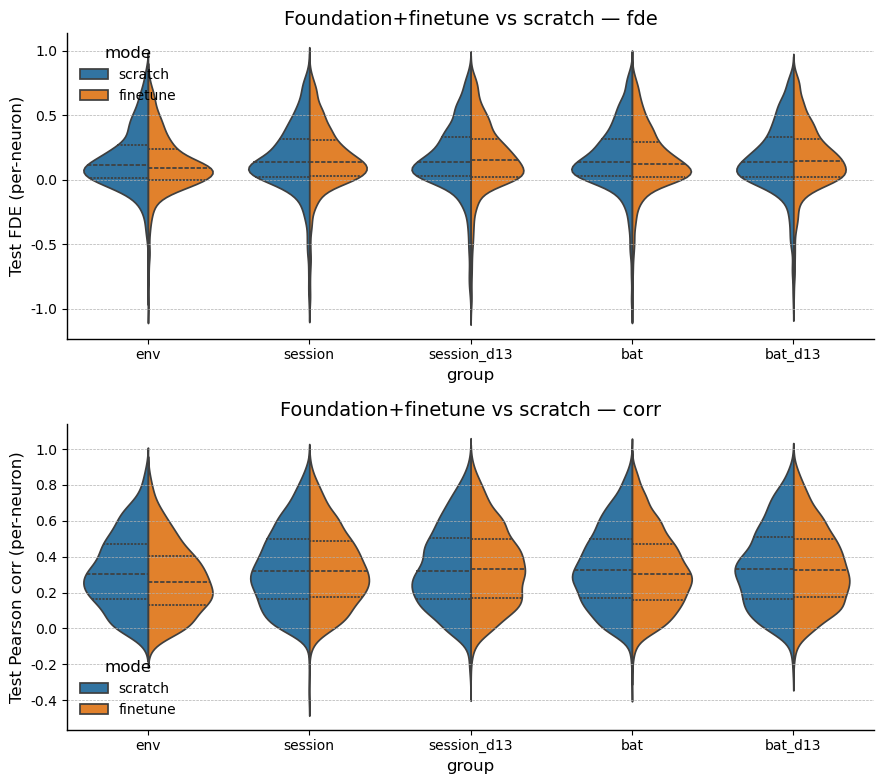

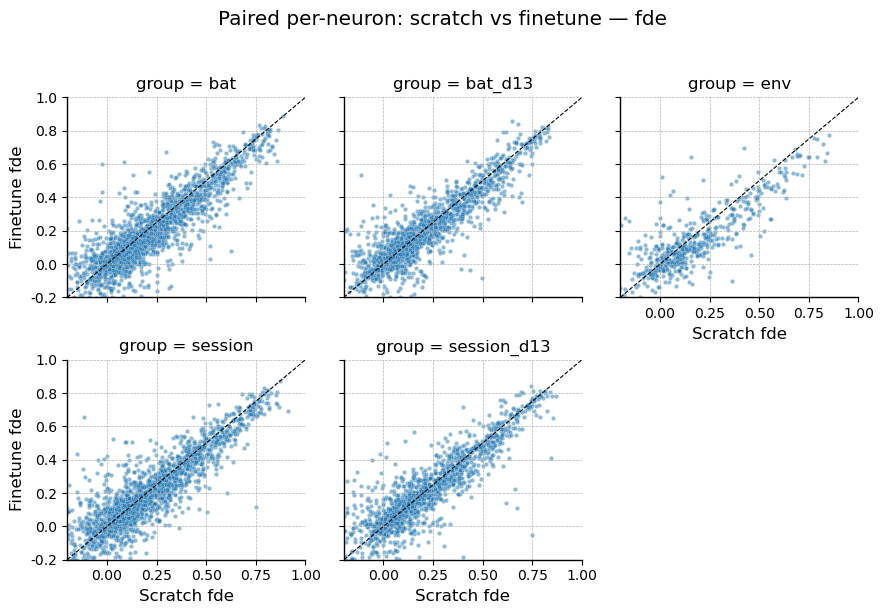

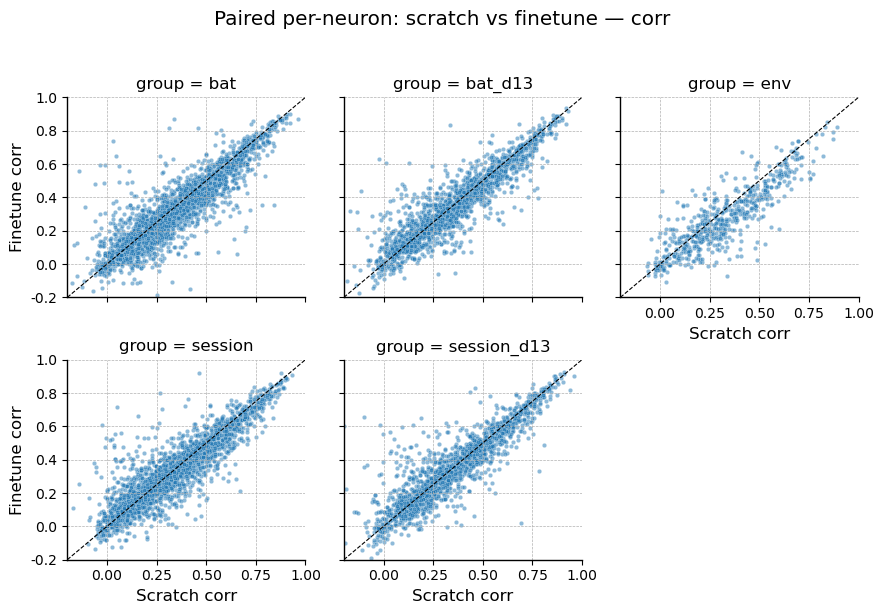

In [15]:
def load_all_results():
    dfs = []
    for g in ('env', 'session', 'session_d13', 'bat', 'bat_d13'):
        p = os.path.join(OUT_ROOT, g, f'results_{g}.pkl')
        if os.path.exists(p):
            dfs.append(pd.read_pickle(p))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


METRICS = [
    ('fde',  'Test FDE (per-neuron)',          (-0.2, 1.0)),
    ('corr', 'Test Pearson corr (per-neuron)', (-0.2, 1.0)),
]


def crop_for_plot(df, metric):
    """Standing rule: always pre-filter to fde > -1 before plotting FDE."""
    return df[df['fde'] > -1] if metric == 'fde' else df


df_all = load_all_results()
if not df_all.empty:
    fig, axes = plt.subplots(len(METRICS), 1, figsize=(9, 4 * len(METRICS)))
    for ax, (metric, ylabel, _) in zip(np.atleast_1d(axes), METRICS):
        sub = crop_for_plot(df_all, metric)
        sns.violinplot(data=sub, x='group', y=metric, hue='mode',
                       split=True, inner='quartile', ax=ax)
        ax.set_ylabel(ylabel)
        ax.set_title(f'Foundation+finetune vs scratch — {metric}')
    plt.tight_layout()

    for metric, _, (lo, hi) in METRICS:
        src = crop_for_plot(df_all, metric)
        pivot = (src.pivot_table(index=['group', 'heldout', 'target_session', 'neuron_idx'],
                                  columns='mode', values=metric)
                 .reset_index())
        pivot = pivot.dropna(subset=['finetune', 'scratch'])
        if pivot.empty:
            continue
        g = sns.FacetGrid(pivot, col='group', col_wrap=3, height=3, sharex=True, sharey=True)
        g.map_dataframe(sns.scatterplot, x='scratch', y='finetune', alpha=0.5, s=10)
        for ax in g.axes.flat:
            ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        g.set_axis_labels(f'Scratch {metric}', f'Finetune {metric}')
        g.fig.suptitle(f'Paired per-neuron: scratch vs finetune — {metric}', y=1.02)
        plt.tight_layout()
else:
    print('No results on disk yet.')

# Paired statistics: finetune vs scratch

Paired comparisons at two aggregation levels:
1. **Neuron level** \u2014 pair `(target_session, neuron_idx)` across modes, test per-neuron FDE difference.
2. **Session level** \u2014 take median FDE across neurons within each target session, pair across modes.

Wilcoxon signed-rank is the primary test (non-parametric, robust to extreme FDE tails). Paired t on FDE clipped to [-1, 1] is included for magnitude intuition.

In [16]:
from scipy.stats import wilcoxon, ttest_rel


def paired_stats_neuron(df, metric='fde'):
    """Per-neuron paired Finetune-vs-Scratch stats on `metric`, broken down by group."""
    pair = (df.pivot_table(index=['group', 'heldout', 'target_session', 'neuron_idx'],
                            columns='mode', values=metric)
              .reset_index())
    pair = pair.dropna(subset=['finetune', 'scratch'])
    pair = pair[np.isfinite(pair['finetune']) & np.isfinite(pair['scratch'])]
    rows = []
    for group, sub in pair.groupby('group'):
        d = sub['finetune'] - sub['scratch']
        w2 = wilcoxon(d, alternative='two-sided')
        w_gt = wilcoxon(d, alternative='greater')  # H1: finetune > scratch
        t_clip = ttest_rel(sub['finetune'].clip(-1, 1), sub['scratch'].clip(-1, 1))
        rows.append(dict(
            group=group,
            n_neurons=len(sub),
            median_finetune=sub['finetune'].median(),
            median_scratch=sub['scratch'].median(),
            median_diff=d.median(),
            frac_finetune_wins=(d > 0).mean(),
            wilcoxon_W=w2.statistic,
            wilcoxon_p_two=w2.pvalue,
            wilcoxon_p_ft_gt=w_gt.pvalue,
            t_clip=t_clip.statistic,
            t_clip_p=t_clip.pvalue,
        ))
    return pd.DataFrame(rows)


def paired_stats_session(df, metric='fde'):
    """Session-level paired stats: median `metric` per target session, paired across modes."""
    sess = (df.groupby(['group', 'heldout', 'target_session', 'mode'])[metric]
              .median().unstack('mode').reset_index())
    sess = sess.dropna(subset=['finetune', 'scratch'])
    rows = []
    for group, sub in sess.groupby('group'):
        d = sub['finetune'] - sub['scratch']
        if len(sub) >= 1:
            try:
                w2 = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                w_gt = wilcoxon(d, alternative='greater', zero_method='wilcox')
                wp2, wpgt, wW = w2.pvalue, w_gt.pvalue, w2.statistic
            except ValueError:
                wp2, wpgt, wW = np.nan, np.nan, np.nan
            t = ttest_rel(sub['finetune'], sub['scratch']) if len(sub) > 1 else None
        rows.append(dict(
            group=group,
            n_sessions=len(sub),
            mean_finetune=sub['finetune'].mean(),
            mean_scratch=sub['scratch'].mean(),
            mean_diff=d.mean(),
            frac_sessions_finetune_wins=(d > 0).mean(),
            wilcoxon_W=wW,
            wilcoxon_p_two=wp2,
            wilcoxon_p_ft_gt=wpgt,
            t_stat=(t.statistic if t is not None else np.nan),
            t_p=(t.pvalue if t is not None else np.nan),
        ))
    return pd.DataFrame(rows), sess


df_all = load_all_results()
if df_all.empty:
    print('No results on disk yet.')
else:
    for metric in ('fde', 'corr'):
        print(f'################  metric = {metric}  ################')
        neuron_stats = paired_stats_neuron(df_all, metric=metric)
        session_stats, session_table = paired_stats_session(df_all, metric=metric)
        print(f'=== Per-group neuron-level paired stats ({metric}) ===')
        display(neuron_stats.round(4))
        print()
        print(f'=== Per-group session-level paired stats ({metric}) ===')
        display(session_stats.round(4))
        print()
        print(f'=== Session medians ({metric}) by group, heldout, target_session ===')
        display(session_table.round(4))
        print()

################  metric = fde  ################
=== Per-group neuron-level paired stats (fde) ===


,group,n_neurons,median_finetune,median_scratch,median_diff,frac_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_clip,t_clip_p
0,bat,2253,0.1193,0.1333,-0.0216,0.3813,957574.0,0.0000,1.0000,-2.9335,0.0034
1,bat_d13,1695,0.1393,0.1329,-0.0067,0.4720,662091.0,0.0050,0.9975,0.9073,0.3644
2,env,558,0.0889,0.1092,-0.0415,0.3100,47042.0,0.0000,1.0000,-6.0601,0.0000
3,session,2253,0.1341,0.1293,-0.0093,0.4456,1140385.0,0.0000,1.0000,1.0467,0.2954
4,session_d13,1695,0.1427,0.1344,-0.0046,0.4737,693486.0,0.2113,0.8944,2.5978,0.0095



=== Per-group session-level paired stats (fde) ===


,group,n_sessions,mean_finetune,mean_scratch,mean_diff,frac_sessions_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_stat,t_p
0,bat,18,0.1545,0.1712,-0.0167,0.2222,37.0,0.0342,0.9848,-2.0018,0.0615
1,bat_d13,14,0.1786,0.1744,0.0042,0.5000,52.0,1.0000,0.5242,0.3574,0.7265
2,env,4,0.1069,0.1305,-0.0236,0.2500,2.0,0.3750,0.8750,-1.0952,0.3535
3,session,18,0.1675,0.1696,-0.0020,0.5556,78.0,0.7660,0.6331,-0.2243,0.8252
4,session_d13,14,0.1779,0.1733,0.0046,0.4286,36.0,0.3258,0.8521,0.2811,0.7831



=== Session medians (fde) by group, heldout, target_session ===


...

,group,n_neurons,median_finetune,median_scratch,median_diff,frac_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_clip,t_clip_p
0,bat,2253,0.3054,0.3249,-0.0177,0.3897,906670.0,0.0000,1.0000,-7.4885,0.0000
1,bat_d13,1695,0.3253,0.3293,-0.0064,0.4466,640302.5,0.0013,0.9994,-0.8836,0.3770
2,env,558,0.2613,0.3024,-0.0459,0.2867,39475.0,0.0000,1.0000,-9.5469,0.0000
3,session,2253,0.3214,0.3188,-0.0075,0.4416,1127417.0,0.0001,1.0000,-0.1780,0.8588
4,session_d13,1695,0.3301,0.3175,-0.0030,0.4737,671884.0,0.1021,0.9490,1.5662,0.1175



=== Per-group session-level paired stats (corr) ===


,group,n_sessions,mean_finetune,mean_scratch,mean_diff,frac_sessions_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_stat,t_p
0,bat,18,0.3342,0.3537,-0.0195,0.2222,34.0,0.0237,0.9896,-2.2539,0.0377
1,bat_d13,14,0.3535,0.3585,-0.0050,0.3571,43.0,0.5830,0.7292,-0.4693,0.6466
2,env,4,0.2732,0.3194,-0.0461,0.2500,1.0,0.2500,0.9375,-2.3527,0.1001
3,session,18,0.3467,0.3475,-0.0008,0.3333,61.0,0.3038,0.8581,-0.0788,0.9381
4,session_d13,14,0.3620,0.3598,0.0021,0.5000,49.0,0.8552,0.5961,0.2228,0.8272



=== Session medians (corr) by group, heldout, target_session ===


mode,group,heldout,target_session,finetune,scratch
0,bat,00000,Dataset_3_00000_240402,0.3484,0.3314
1,bat,00000,Dataset_3_00000_240403,0.4267,0.4572
2,bat,00000,Dataset_3_00000_240404,0.3559,0.3696
3,bat,00000,Dataset_3_00000_240405,0.4002,0.4036
4,bat,14445,Dataset_2_14445_231208,0.2796,0.3609
...,...,...,...,...,...
63,session_d13,Dataset_3_14543_240421,Dataset_3_14543_240421,0.4349,0.4874
64,session_d13,Dataset_3_29959_240402,Dataset_3_29959_240402,0.2403,0.2292
65,session_d13,Dataset_3_29959_240403,Dataset_3_29959_240403,0.3258,0.3454
66,session_d13,Dataset_3_29959_240404,Dataset_3_29959_240404,0.3492,0.3252


# Scaling with number of training sessions

For each universe (`SESSIONS` with 18, `SESSIONS_D13` with 14) we train end-to-end models on session counts $N \in \{2, 4, 8, N_\text{full}\}$ and compare against the $N=1$ scratch models already saved by the session sweeps. $N \in \{2,4,8\}$ uses **5 different random subsamples** of sessions per value; $N_\text{full}$ is deterministic (one model trained on the full universe). Each trained model scores one FDE value per included session (evaluated on that session's test split), so each target session appears in $\sim 5 \cdot N / N_\text{full}$ subsamples on average at $N \in \{2,4,8\}$.

In [17]:
def stratified_subsamples(universe, N, n_samples, rng):
    """Draw n_samples size-N subsets from `universe` such that every session
    appears in at least one subset.

    Stage 1: round-robin anchors \u2014 sample i anchors universe[i % N_full] (shuffled order),
             remaining N-1 slots filled uniformly without replacement from the rest.
    Stage 2: coverage repair \u2014 for each session still uncovered, find a subset where we can
             swap it in for a session that appears in >= 1 other subset (so coverage never drops).
    """
    universe = list(universe)
    N_full = len(universe)
    assert N <= N_full

    anchors = list(universe)
    rng.shuffle(anchors)
    samples = []
    for i in range(n_samples):
        anchor = anchors[i % N_full]
        others_pool = [s for s in universe if s != anchor]
        rest = list(rng.choice(others_pool, size=N - 1, replace=False))
        samples.append(sorted([anchor] + rest))

    covered = set().union(*samples) if samples else set()
    missing = sorted(set(universe) - covered)

    for m in missing:
        best = None  # (subset_idx, slot_idx, count_elsewhere)
        for si, sub in enumerate(samples):
            if m in sub:
                continue
            for ji, s in enumerate(sub):
                count_elsewhere = sum(1 for oi, osub in enumerate(samples)
                                      if oi != si and s in osub)
                if count_elsewhere >= 1 and (best is None or count_elsewhere > best[2]):
                    best = (si, ji, count_elsewhere)
        if best is None:
            raise RuntimeError(f'Cannot insert missing session {m} without dropping coverage')
        si, ji, _ = best
        samples[si][ji] = m
        samples[si] = sorted(samples[si])

    # sanity
    assert set().union(*samples) == set(universe), 'coverage repair failed'
    return samples


def run_scaling_sweep(group_name, scratch_group_name, universe_sessions,
                       sizes=(2, 4, 8), n_samples=10, seed=SEED,
                       max_workers=MAX_WORKERS):
    """
    Scaling curve: train models on size-N subsets of `universe_sessions` (n_samples stratified
    subsamples each, guaranteed to cover every session) plus the full universe.
    Evaluate each trained readout on its own session's test split.
    N=1 baseline is read from the saved `scratch_group_name` scratch checkpoints (no retraining).
    """
    universe = list(universe_sessions)
    N_full = len(universe)
    out_dir = os.path.join(OUT_ROOT, f'scaling_{group_name}')
    os.makedirs(out_dir, exist_ok=True)
    rows = []

    # ---- N=1: reuse saved scratch checkpoints from the session sweep ----
    for t in universe:
        scratch_path = ckpt_path(scratch_group_name, t, suffix=f'__{t}_scratch')
        if not os.path.exists(scratch_path):
            print(f'  [scaling_{group_name}] MISSING scratch for {t}: {scratch_path}')
            continue
        model = build_bat_former({t: unit_num_dict[t]}, behavior_dim)
        model.load_state_dict(torch.load(scratch_path, map_location=DEVICE))
        model.to(DEVICE)
        fde, pc = eval_on_session(model, t, dataloaders, split='test')
        for i, (f, c) in enumerate(zip(fde, pc)):
            rows.append(dict(scaling_group=group_name, n_sessions=1, sample_id=0,
                             target_session=t, neuron_idx=i,
                             fde=float(f), corr=float(c)))

    # ---- build stratified (N, sample_id) -> session subset ----
    rng = np.random.default_rng(seed)
    subsamples = {}
    for N in sizes:
        subs = stratified_subsamples(universe, N, n_samples, rng)
        for sid, sub in enumerate(subs):
            subsamples[(N, sid)] = sub
    subsamples[(N_full, 0)] = list(universe)

    # ---- train each subset in parallel ----
    tasks = []
    for (N, sid), sub in subsamples.items():
        path = os.path.join(out_dir,
            f'bat_former_seed_{seed}_wd_sweep_scaling_{group_name}_N{N}_s{sid}.pth')
        tid = f'SCAL:{group_name}:N{N}:s{sid}'
        tasks.append((tid, lambda src=list(sub), p=path: train_foundation(src, p, seed=seed)))
    results = run_tasks_parallel(tasks, max_workers=max_workers, label=f'scaling_{group_name}')

    # ---- evaluate every (model, readout) on that readout's own session ----
    for (N, sid), sub in subsamples.items():
        r = results.get(f'SCAL:{group_name}:N{N}:s{sid}')
        if r is None:
            continue
        _, model = r
        for t in sub:
            fde, pc = eval_on_session(model, t, dataloaders, split='test')
            for i, (f, c) in enumerate(zip(fde, pc)):
                rows.append(dict(scaling_group=group_name, n_sessions=N, sample_id=sid,
                                 target_session=t, neuron_idx=i,
                                 fde=float(f), corr=float(c)))

    df = pd.DataFrame(rows)
    df_path = os.path.join(out_dir, f'results_scaling_{group_name}.pkl')
    df.to_pickle(df_path)
    print(f'Saved {len(df)} rows to {df_path}')
    return df

In [18]:
RUN_SCALING_SESSION = False  # 5*3 + 1 = 16 new foundation trainings over SESSIONS (18)

if RUN_SCALING_SESSION:
    df_scaling_session = run_scaling_sweep(
        group_name='session',
        scratch_group_name='session',
        universe_sessions=SESSIONS,
    )

In [19]:
RUN_SCALING_SESSION_D13 = False  # 5*3 + 1 = 16 new foundation trainings over SESSIONS_D13 (14)

if RUN_SCALING_SESSION_D13:
    df_scaling_d13 = run_scaling_sweep(
        group_name='session_d13',
        scratch_group_name='session_d13',
        universe_sessions=SESSIONS_D13,
    )

## Scaling analysis: plots + paired stats

- **Curve**: per-session median FDE (across neurons) at each $N$, with each subsample contributing one point; overlaid mean per $N$.
- **Paired stats**: for each $N \in \{2,4,8,N_\text{full}\}$, compare per-session median FDE against the matching $N=1$ scratch value for the same target session. With 5 subsamples, a target session contributes up to 5 paired comparisons per $N$ (or 0 if it was never drawn); we use Wilcoxon signed-rank + paired t on those pairs.

=== Scaling paired stats (fde; H1: N-model mean > scratch on same target) ===


,scaling_group,n_sessions,n_targets,mean_N,mean_scratch,mean_diff,frac_targets_N_better,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_N_better,t_stat,t_p
0,session,2,18,0.1743,0.1727,0.0016,0.5000,81.0,0.8650,0.4325,0.2377,0.8149
1,session,4,18,0.1714,0.1727,-0.0012,0.6111,83.0,0.9323,0.4661,-0.1965,0.8465
2,session,8,18,0.1757,0.1727,0.0030,0.5000,80.0,0.8317,0.6006,0.4123,0.6853
3,session,18,18,0.1699,0.1727,-0.0028,0.3889,71.0,0.5509,0.7387,-0.2666,0.7930
4,session_d13,2,14,0.1743,0.1757,-0.0014,0.4286,45.0,0.6698,0.6871,-0.1563,0.8782
5,session_d13,4,14,0.1815,0.1757,0.0058,0.4286,52.0,1.0000,0.5242,0.5629,0.5831
6,session_d13,8,14,0.1846,0.1757,0.0089,0.5000,52.0,1.0000,0.5000,0.7954,0.4407
7,session_d13,14,14,0.1839,0.1757,0.0083,0.4286,52.0,1.0000,0.5000,0.6266,0.5418


=== Scaling paired stats (corr; H1: N-model mean > scratch on same target) ===


,scaling_group,n_sessions,n_targets,mean_N,mean_scratch,mean_diff,frac_targets_N_better,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_N_better,t_stat,t_p
0,session,2,18,0.3468,0.3475,-0.0007,0.5000,81.0,0.8650,0.5841,-0.1161,0.9089
1,session,4,18,0.3423,0.3475,-0.0052,0.2778,56.0,0.2121,0.9018,-0.9524,0.3542
2,session,8,18,0.3546,0.3475,0.0071,0.4444,84.0,0.9661,0.5339,0.8554,0.4042
3,session,18,18,0.3480,0.3475,0.0005,0.3333,66.0,0.4171,0.8036,0.0466,0.9634
4,session_d13,2,14,0.3527,0.3617,-0.0090,0.3571,33.0,0.2412,0.8917,-0.9998,0.3356
5,session_d13,4,14,0.3565,0.3617,-0.0052,0.3571,30.0,0.1726,0.9235,-0.5681,0.5797
6,session_d13,8,14,0.3586,0.3617,-0.0031,0.2857,29.0,0.1531,0.9324,-0.3206,0.7536
7,session_d13,14,14,0.3576,0.3617,-0.0041,0.4286,35.0,0.2958,0.8662,-0.4552,0.6565


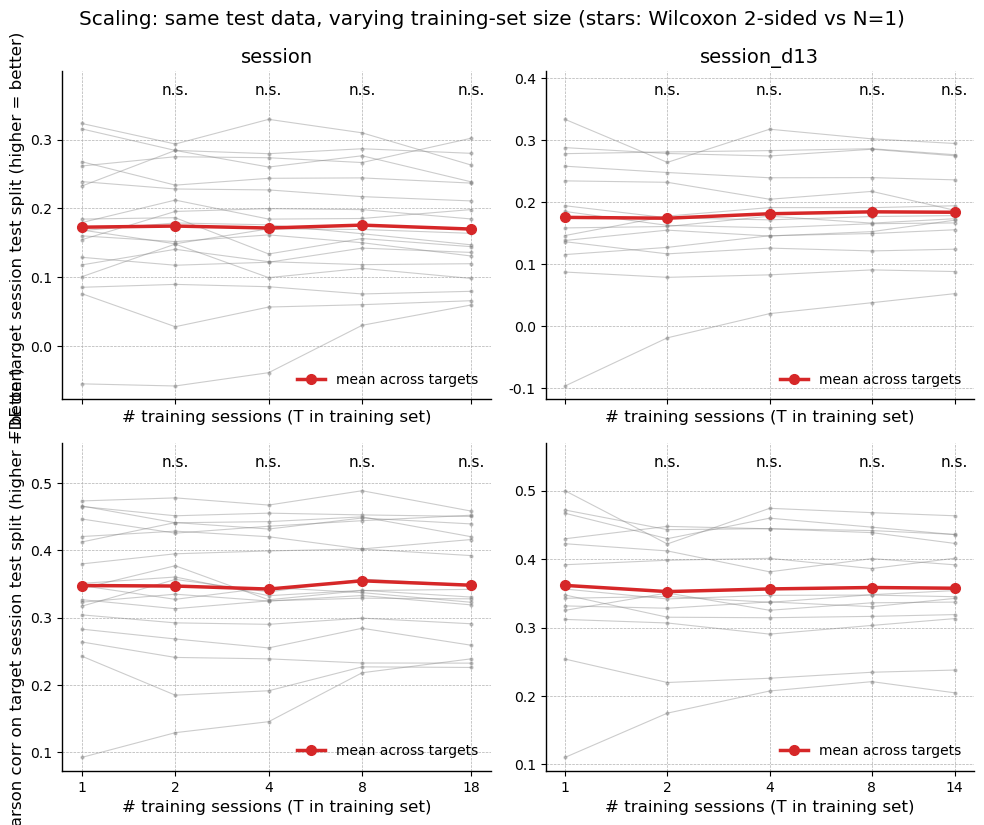

In [20]:
def load_scaling_results():
    dfs = []
    for g in ('session', 'session_d13'):
        p = os.path.join(OUT_ROOT, f'scaling_{g}', f'results_scaling_{g}.pkl')
        if os.path.exists(p):
            dfs.append(pd.read_pickle(p))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def scaling_per_target(df, metric='fde'):
    """Median `metric` across neurons per (group, N, sample_id, target), then mean over subsamples
    that contained the target. One value per (group, N, target) — paired across N by target."""
    med = (df.groupby(['scaling_group', 'n_sessions', 'sample_id', 'target_session'])[metric]
             .median().reset_index(name=f'{metric}_median'))
    per_T = (med.groupby(['scaling_group', 'n_sessions', 'target_session'])[f'{metric}_median']
                .agg(['mean', 'count']).reset_index()
                .rename(columns={'mean': metric, 'count': 'n_subsamples'}))
    return per_T


def scaling_paired_stats(per_T, metric='fde'):
    """Pair per-target `metric` at N>1 vs N=1 scratch on the same target; Wilcoxon + paired t."""
    base = (per_T[per_T['n_sessions'] == 1]
            .set_index(['scaling_group', 'target_session'])[metric]
            .rename(f'{metric}_scratch'))
    rows = []
    for (grp, N), sub in per_T[per_T['n_sessions'] > 1].groupby(['scaling_group', 'n_sessions']):
        joined = sub.join(base, on=['scaling_group', 'target_session']).dropna(subset=[metric, f'{metric}_scratch'])
        d = joined[metric] - joined[f'{metric}_scratch']
        try:
            w2 = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
            w_gt = wilcoxon(d, alternative='greater', zero_method='wilcox')
            wW, wp2, wpgt = w2.statistic, w2.pvalue, w_gt.pvalue
        except ValueError:
            wW = wp2 = wpgt = np.nan
        t = ttest_rel(joined[metric], joined[f'{metric}_scratch']) if len(joined) > 1 else None
        rows.append(dict(
            scaling_group=grp, n_sessions=int(N),
            n_targets=len(joined),
            mean_N=joined[metric].mean(),
            mean_scratch=joined[f'{metric}_scratch'].mean(),
            mean_diff=d.mean(),
            frac_targets_N_better=(d > 0).mean(),
            wilcoxon_W=wW, wilcoxon_p_two=wp2, wilcoxon_p_N_better=wpgt,
            t_stat=(t.statistic if t is not None else np.nan),
            t_p=(t.pvalue if t is not None else np.nan),
        ))
    return pd.DataFrame(rows)


def p_to_stars(p):
    if p is None or not np.isfinite(p):
        return ''
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'


SCALING_METRICS = [
    ('fde',  'FDE on target session test split (higher = better)'),
    ('corr', 'Pearson corr on target session test split (higher = better)'),
]


df_sc = load_scaling_results()
if df_sc.empty:
    print('No scaling results on disk yet. Flip RUN_SCALING_* flags and rerun.')
else:
    groups = sorted(df_sc['scaling_group'].unique())
    fig, axes = plt.subplots(len(SCALING_METRICS), len(groups),
                              figsize=(5 * len(groups), 4.2 * len(SCALING_METRICS)),
                              sharex='col', squeeze=False)

    for row, (metric, ylabel) in enumerate(SCALING_METRICS):
        src = crop_for_plot(df_sc, metric)
        per_T = scaling_per_target(src, metric=metric)
        stats = scaling_paired_stats(per_T, metric=metric)
        for ax, grp in zip(axes[row], groups):
            sub = per_T[per_T['scaling_group'] == grp]
            ns = sorted(sub['n_sessions'].unique())
            wide = sub.pivot(index='target_session', columns='n_sessions', values=metric).reindex(columns=ns)
            for _, r in wide.iterrows():
                ax.plot(ns, r.values, color='gray', alpha=0.4, lw=0.8, marker='.', ms=4)
            means = [sub[sub['n_sessions'] == n][metric].mean() for n in ns]
            ax.plot(ns, means, color='C3', lw=2.5, marker='o', ms=7, label='mean across targets')

            y_top = sub[metric].max()
            y_bot = sub[metric].min()
            y_txt = y_top + 0.08 * (y_top - y_bot)
            gs = stats[stats['scaling_group'] == grp].set_index('n_sessions')
            for n in ns:
                if n == 1:
                    continue
                p = gs.loc[n, 'wilcoxon_p_two'] if n in gs.index else np.nan
                ax.text(n, y_txt, p_to_stars(p), ha='center', va='bottom', fontsize=11)
            ax.set_ylim(top=y_top + 0.18 * (y_top - y_bot))

            ax.set_xscale('log', base=2)
            ax.set_xticks(ns); ax.set_xticklabels(ns)
            ax.set_xlabel('# training sessions (T in training set)')
            if row == 0:
                ax.set_title(grp)
            ax.legend(frameon=False, loc='lower right')
        axes[row, 0].set_ylabel(ylabel)

        print(f'=== Scaling paired stats ({metric}; H1: N-model mean > scratch on same target) ===')
        display(stats.round(4))

    fig.suptitle('Scaling: same test data, varying training-set size (stars: Wilcoxon 2-sided vs N=1)')
    plt.tight_layout()

# Full vs transfer vs scratch (neuron-level violins)

Per-neuron test metrics under three training regimes, on the 18-session sweep:
- **full (N=18)** — foundation trained on all 18 sessions, evaluated on each session's own test split (from `scaling_session` at N=18).
- **transfer** — foundation trained on the 17 non-target sessions, target readout fine-tuned (frozen core).
- **scratch** — single-session model trained only on the target session.

All three share the same per-session train/valid/test split, so the violins are over the same set of (session, neuron) pairs.

Neuron counts per condition:


condition
full (N=18)    2253
scratch        2253
transfer       2253
Name: n_neurons, dtype: int64

Medians:


,corr,fde
condition,,
full (N=18),0.3151,0.1290
scratch,0.3188,0.1293
transfer,0.3214,0.1341


Paired-difference summary (neuron-level):


,metric,contrast,n,median,mean,frac_pos,wilcoxon_W,wilcoxon_p_two
0,corr,full − scratch,2253,-0.0083,-0.0033,0.4372,1079527.5,0.0000
1,corr,full − transfer,2253,-0.0019,-0.0029,0.4758,1178687.5,0.0225
2,corr,scratch − transfer,2253,0.0075,0.0004,0.5499,1127417.0,0.0001
3,fde,full − scratch,2197,-0.0081,0.0014,0.4502,1079865.0,0.0000
4,fde,full − transfer,2206,-0.0012,-0.0000,0.4918,1194410.0,0.4470
5,fde,scratch − transfer,2197,0.0091,-0.0007,0.5530,1090216.0,0.0001


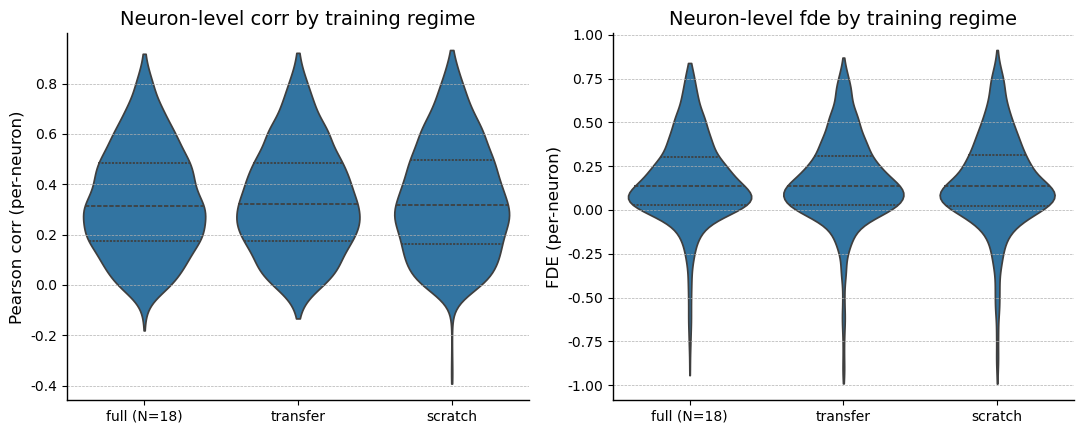

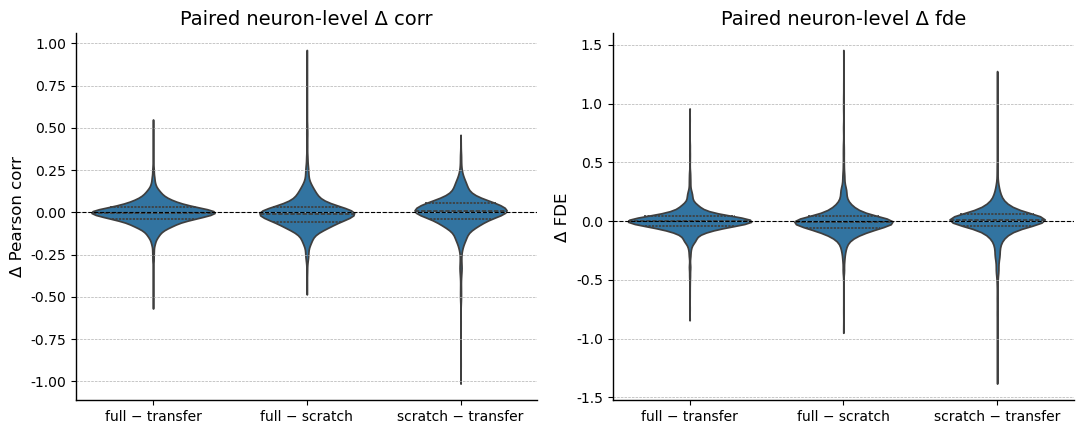

In [21]:
df_all = load_all_results()
df_sc = load_scaling_results()

N_FULL = len(SESSIONS)  # 18

frames = []
if not df_sc.empty:
    full = df_sc[(df_sc['scaling_group'] == 'session') & (df_sc['n_sessions'] == N_FULL)][
        ['target_session', 'neuron_idx', 'fde', 'corr']].copy()
    if not full.empty:
        full['condition'] = f'full (N={N_FULL})'
        frames.append(full)
if not df_all.empty:
    for mode, label in [('finetune', 'transfer'), ('scratch', 'scratch')]:
        sub = df_all[(df_all['group'] == 'session') & (df_all['mode'] == mode)][
            ['target_session', 'neuron_idx', 'fde', 'corr']].copy()
        if not sub.empty:
            sub['condition'] = label
            frames.append(sub)

if not frames:
    print('Not enough data on disk — need scaling_session (N=18) and session sweep results.')
else:
    df_cmp = pd.concat(frames, ignore_index=True)
    full_label = f'full (N={N_FULL})'
    order = [c for c in [full_label, 'transfer', 'scratch'] if c in df_cmp['condition'].unique()]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, metric, ylabel in zip(
        axes,
        ('corr', 'fde'),
        ('Pearson corr (per-neuron)', 'FDE (per-neuron)'),
    ):
        sns.violinplot(data=crop_for_plot(df_cmp, metric),
                       x='condition', y=metric, order=order,
                       inner='quartile', ax=ax, cut=0)
        ax.set_xlabel('')
        ax.set_ylabel(ylabel)
        ax.set_title(f'Neuron-level {metric} by training regime')
    plt.tight_layout()

    print('Neuron counts per condition:')
    display(df_cmp.groupby('condition').size().rename('n_neurons'))
    print('Medians:')
    display(df_cmp.groupby('condition')[['corr', 'fde']].median().round(4))

    # ---- Paired neuron-level differences ----
    diff_specs = [
        ('full − transfer',    full_label, 'transfer'),
        ('full − scratch',     full_label, 'scratch'),
        ('scratch − transfer', 'scratch',  'transfer'),
    ]
    diff_frames = []
    pivots = {
        m: crop_for_plot(df_cmp, m).pivot_table(
            index=['target_session', 'neuron_idx'], columns='condition', values=m)
        for m in ('corr', 'fde')
    }
    for metric, p in pivots.items():
        for label, a, b in diff_specs:
            if a not in p.columns or b not in p.columns:
                continue
            d = (p[a] - p[b]).dropna().rename('diff').reset_index()
            d['contrast'] = label
            d['metric'] = metric
            diff_frames.append(d)

    if diff_frames:
        df_diff = pd.concat(diff_frames, ignore_index=True)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        for ax, metric, ylabel in zip(
            axes,
            ('corr', 'fde'),
            ('Δ Pearson corr', 'Δ FDE'),
        ):
            sns.violinplot(data=df_diff[df_diff['metric'] == metric],
                           x='contrast', y='diff',
                           order=[s[0] for s in diff_specs],
                           inner='quartile', ax=ax, cut=0)
            ax.axhline(0, color='k', lw=0.8, ls='--')
            ax.set_xlabel('')
            ax.set_ylabel(ylabel)
            ax.set_title(f'Paired neuron-level Δ {metric}')
        plt.tight_layout()

        rows = []
        for (metric, contrast), sub in df_diff.groupby(['metric', 'contrast']):
            d = sub['diff'].values
            try:
                w = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                wW, wp = float(w.statistic), float(w.pvalue)
            except ValueError:
                wW, wp = np.nan, np.nan
            rows.append(dict(
                metric=metric, contrast=contrast, n=len(d),
                median=float(np.median(d)), mean=float(np.mean(d)),
                frac_pos=float((d > 0).mean()),
                wilcoxon_W=wW, wilcoxon_p_two=wp,
            ))
        print('Paired-difference summary (neuron-level):')
        display(pd.DataFrame(rows).round(4))

# 2 x 4 matrix: data fraction x training mode

For each of the 18 target sessions, evaluate four training regimes
(**full** / **transfer-frozen** / **transfer-10\u202f% LR core** / **scratch**)
at two target-session training-data fractions: **100\u202f%** and **25\u202f%**.
All other 17 sessions stay at 100\u202f%; the test set is always the target's
full test split.

Already-trained checkpoints are reused when the cell matches:

| cell                       | source                                     |
| ---                        | ---                                        |
| `(full,  100%)`            | `scaling_session/\u2026N18_s0.pth`              |
| `(frozen, 100%)`           | `session/\u2026__{target}_finetune.pth`         |
| `(scratch, 100%)`          | `session/\u2026__{target}_scratch.pth`          |

The remaining 5 cells (5 \u00d7 18 = 90 trainings) are new: 1 cell adds the
low-LR-core finetune at 100\u202f%, plus all 4 modes at 25\u202f%. Per-target
foundation init for both finetune modes comes from
`session/\u2026{target}.pth` (held-out 17-session foundations already trained
upstream).

WD grids: `WD_GRID = [0.01, 0.1]` for full / frozen / lowlr; the wider
`WD_SCRATCH_GRID = [0.01, 0.1, 1.0]` for scratch only.

In [22]:
from torch.utils.data import DataLoader, Subset
import copy as _copy
import tqdm as _tqdm

FRACTION_2X4 = 0.25
CORE_LR_FRAC = 0.1
TWOXFOUR_DIR = os.path.join(OUT_ROOT, 'twoxfour')
os.makedirs(TWOXFOUR_DIR, exist_ok=True)


def subsample_train_dataloader(dl, fraction, seed=SEED):
    """Return a new DataLoader using a fixed `fraction` of `dl.dataset`. Seeded so all
    four 25%-modes per target see exactly the same subset of training trajectories."""
    if fraction >= 1.0:
        return dl
    ds = dl.dataset
    n = len(ds)
    n_keep = max(1, int(round(fraction * n)))
    rng = np.random.default_rng(seed)
    indices = sorted(rng.choice(n, size=n_keep, replace=False).tolist())
    return DataLoader(
        Subset(ds, indices),
        batch_size=dl.batch_size, shuffle=True,
        collate_fn=getattr(dl, 'collate_fn', None),
        num_workers=getattr(dl, 'num_workers', 0),
        drop_last=getattr(dl, 'drop_last', False),
    )


def twoxfour_path(target, mode, fraction_pct):
    name = (f'bat_former_seed_{SEED}_wd_sweep_2x4_'
            f'frac{fraction_pct}_{mode}_{target}.pth')
    return os.path.join(TWOXFOUR_DIR, name)


def finetune_lowlr_trainer(
    model, dataloaders, device, target_session,
    core_lr_frac=CORE_LR_FRAC,
    n_epochs=200, lr=1e-2, weight_decay=0.0,
    loss_fn=None, valid_fn=None, valid_stat='mean',
    early_stopping_patience=None,
    save_model=False, model_name='best_lowlr_weights.pth',
    **_unused,
):
    """Fine-tune target readout at `lr` and the rest of the model (excluding other
    session readouts) at `core_lr_frac * lr`. Other readouts are frozen.

    Mirrors finetune_readout_trainer but adds the transformer core to the optimizer
    in a separate parameter group at the lower LR. Iterates only over
    `dataloaders['train'|'valid'][target_session]`.
    """
    model = model.to(device)
    loss_fn = loss_fn.to(device)
    target_param_ids = {id(p) for p in model.readouts[target_session].parameters()}
    other_readout_ids = {id(p) for sess, mod in model.readouts.items()
                         if sess != target_session for p in mod.parameters()}
    for p in model.parameters():
        p.requires_grad = id(p) not in other_readout_ids
    target_params = list(model.readouts[target_session].parameters())
    core_params = [p for p in model.parameters()
                   if id(p) not in target_param_ids
                   and id(p) not in other_readout_ids]
    optimizer = torch.optim.AdamW([
        {'params': core_params,   'lr': lr * core_lr_frac, 'weight_decay': weight_decay},
        {'params': target_params, 'lr': lr,                'weight_decay': weight_decay},
    ])

    best_score, best_weights = -np.inf, None
    val_scores, no_improve = [], 0
    train_loader = dataloaders['train'][target_session]
    valid_loader = dataloaders['valid'][target_session]

    for epoch in _tqdm.tqdm(range(n_epochs), desc=f'FT-LowLR[{target_session}]'):
        model.train()
        for sess, mod in model.readouts.items():
            if sess != target_session:
                mod.eval()
        for batch in train_loader:
            X = batch.behavior.to(device); y = batch.spike.to(device); mask = batch.mask.to(device)
            y_pred = model(target_session, X, mask)
            loss = loss_fn(y_pred[mask == 1.0], y[mask == 1.0])
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval()
        y_v_list, y_p_list = [], []
        with torch.no_grad():
            for batch in valid_loader:
                X = batch.behavior.to(device); y = batch.spike.to(device); mask = batch.mask.to(device)
                y_pred = model(target_session, X, mask)
                y_v_list.append(y.detach()[mask == 1.0].cpu().numpy())
                y_p_list.append(y_pred.detach()[mask == 1.0].cpu().numpy())
        scores = valid_fn(np.vstack(y_v_list), np.vstack(y_p_list))
        val = float(np.nanmean(scores) if valid_stat == 'mean' else np.nanmedian(scores))
        val_scores.append(val)
        if val > best_score:
            best_score = val
            best_weights = _copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if early_stopping_patience and no_improve >= early_stopping_patience:
                print(f'Early stopping at epoch {epoch + 1}')
                break

    if save_model:
        torch.save(model.state_dict(), model_name)
    if best_weights is not None:
        model.load_state_dict(best_weights)
    return best_score, best_weights, val_scores

In [23]:
def _sweep_wd_train_2x4(build_fn, dl_sub, save_path, n_epochs, mode,
                          target_session=None, wd_grid=WD_GRID,
                          core_lr_frac=CORE_LR_FRAC):
    """WD sweep dispatching to the right trainer for `mode`.
    mode in {'full','scratch'}: bat_former_trainer
    mode == 'frozen':            finetune_readout_trainer
    mode == 'lowlr':             finetune_lowlr_trainer
    """
    sweep = []
    for wd in wd_grid:
        sweep_save = wd_path(save_path, wd)
        model = build_fn()
        cfg = dict(
            model=model, dataloaders=dl_sub, device=DEVICE,
            n_epochs=n_epochs, lr=LR, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=EARLY_STOP_PATIENCE,
            save_model=True, model_name=sweep_save,
        )
        if mode == 'frozen':
            cfg['target_session'] = target_session
            score, _, _ = finetune_readout_trainer(**cfg)
        elif mode == 'lowlr':
            cfg['target_session'] = target_session
            cfg['core_lr_frac'] = core_lr_frac
            score, _, _ = finetune_lowlr_trainer(**cfg)
        else:
            score, _, _ = bat_former_trainer(**cfg)
        sweep.append((float(score), wd, sweep_save))
        del model
        torch.cuda.empty_cache()

    best_score, best_wd, best_sweep_path = max(sweep, key=lambda x: x[0])
    final_model = build_fn()
    final_model.load_state_dict(torch.load(best_sweep_path, map_location=DEVICE))
    final_model.to(DEVICE)
    torch.save(final_model.state_dict(), save_path)
    print(f'  [2x4 sweep] {os.path.basename(save_path)} best_wd={best_wd}  val={best_score:.4f}  '
          + '(' + ', '.join(f'wd={w}->{s:.4f}' for s, w, _ in sweep) + ')')
    return best_score, final_model, best_wd


def _foundation_path_for_target(target_session):
    """Canonical 17-session foundation checkpoint for `target_session` (held out)."""
    return ckpt_path('session', target_session)


def _build_for_finetune(target_session, foundation_path, seed=SEED):
    """Bat_Transformer with all 18 readouts; load 17 from `foundation_path`,
    fresh init for `target_session` readout."""
    unit_sub = {s: unit_num_dict[s] for s in SESSIONS}
    model = build_bat_former(unit_sub, behavior_dim, seed=seed)
    state = torch.load(foundation_path, map_location=DEVICE)
    target_prefix = f'readouts.{target_session}.'
    filtered = {k: v for k, v in state.items() if not k.startswith(target_prefix)}
    msg = model.load_state_dict(filtered, strict=False)
    assert not msg.unexpected_keys, msg.unexpected_keys
    other_missing = [k for k in msg.missing_keys if not k.startswith(target_prefix)]
    assert not other_missing, other_missing
    return model


def train_full_2x4(target, fraction, save_path, wd_grid=WD_GRID):
    """All 18 sessions in train/valid; target subsampled to `fraction`."""
    dl_sub = {
        'train': {s: dataloaders['train'][s] for s in SESSIONS},
        'valid': {s: dataloaders['valid'][s] for s in SESSIONS},
        'test':  {s: dataloaders['test'][s]  for s in SESSIONS},
    }
    if fraction < 1.0:
        dl_sub['train'][target] = subsample_train_dataloader(
            dataloaders['train'][target], fraction, seed=SEED)
    def build():
        return build_bat_former(unit_num_dict, behavior_dim, seed=SEED)
    return _sweep_wd_train_2x4(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_FOUNDATION,
                                mode='full', wd_grid=wd_grid)


def train_scratch_2x4(target, fraction, save_path, wd_grid=WD_SCRATCH_GRID):
    """Scratch on target only, subsampled to `fraction` of train."""
    target_train = subsample_train_dataloader(
        dataloaders['train'][target], fraction, seed=SEED)
    dl_sub = {
        'train': {target: target_train},
        'valid': {target: dataloaders['valid'][target]},
        'test':  {target: dataloaders['test'][target]},
    }
    unit_sub = {target: unit_num_dict[target]}
    def build():
        return build_bat_former(unit_sub, behavior_dim, seed=SEED)
    return _sweep_wd_train_2x4(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_SCRATCH,
                                mode='scratch', wd_grid=wd_grid)


def train_finetune_frozen_2x4(target, fraction, save_path, wd_grid=WD_GRID):
    """Frozen-core finetune of target readout at `fraction` of train."""
    foundation_path = _foundation_path_for_target(target)
    target_train = subsample_train_dataloader(
        dataloaders['train'][target], fraction, seed=SEED)
    dl_sub = {
        'train': {target: target_train},
        'valid': {target: dataloaders['valid'][target]},
        'test':  {target: dataloaders['test'][target]},
    }
    def build():
        m = _build_for_finetune(target, foundation_path)
        freeze_core_for_finetune(m, target)
        return m
    return _sweep_wd_train_2x4(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_FINETUNE,
                                mode='frozen', target_session=target,
                                wd_grid=wd_grid)


def train_finetune_lowlr_2x4(target, fraction, save_path, wd_grid=WD_GRID):
    """Low-LR finetune: core at CORE_LR_FRAC*LR, target readout at LR.
    Other readouts stay frozen so we never touch sessions whose data isn't in this loader."""
    foundation_path = _foundation_path_for_target(target)
    target_train = subsample_train_dataloader(
        dataloaders['train'][target], fraction, seed=SEED)
    dl_sub = {
        'train': {target: target_train},
        'valid': {target: dataloaders['valid'][target]},
        'test':  {target: dataloaders['test'][target]},
    }
    def build():
        # Don't pre-freeze the core; finetune_lowlr_trainer manages parameter groups.
        return _build_for_finetune(target, foundation_path)
    return _sweep_wd_train_2x4(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_FINETUNE,
                                mode='lowlr', target_session=target,
                                wd_grid=wd_grid)

In [24]:
MODES_2X4     = ('full', 'frozen', 'lowlr', 'scratch')
FRACTIONS_2X4 = (1.0, 0.25)


def _scaling_n18_path():
    return os.path.join(OUT_ROOT, 'scaling_session',
                        f'bat_former_seed_{SEED}_wd_sweep_scaling_session_N18_s0.pth')


def _existing_session_sweep_path(target, kind):
    """kind in {'finetune', 'scratch'} \u2014 naming from the `session` group sweep."""
    return ckpt_path('session', target, suffix=f'__{target}_{kind}')


def _model_path_2x4(target, mode, fraction):
    """Where the (target, mode, fraction) checkpoint lives. Reuses existing
    session-sweep checkpoints for the three (mode, 100%) cells."""
    if fraction == 1.0:
        if mode == 'full':    return _scaling_n18_path()
        if mode == 'frozen':  return _existing_session_sweep_path(target, 'finetune')
        if mode == 'scratch': return _existing_session_sweep_path(target, 'scratch')
    fraction_pct = int(round(fraction * 100))
    return twoxfour_path(target, mode, fraction_pct)


def _train_one_2x4(target, mode, fraction, save_path):
    if mode == 'full':
        train_full_2x4(target, fraction, save_path)
    elif mode == 'frozen':
        train_finetune_frozen_2x4(target, fraction, save_path)
    elif mode == 'lowlr':
        train_finetune_lowlr_2x4(target, fraction, save_path)
    elif mode == 'scratch':
        train_scratch_2x4(target, fraction, save_path)


def _eval_2x4(target, mode, model_path):
    """Load checkpoint and return (per-neuron FDE, per-neuron corr) on target's test split."""
    if mode == 'scratch':
        unit_sub = {target: unit_num_dict[target]}
    else:
        unit_sub = unit_num_dict  # full/frozen/lowlr checkpoints carry all 18 readouts
    model = build_bat_former(unit_sub, behavior_dim)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.to(DEVICE)
    fde, pc = eval_on_session(model, target, dataloaders, split='test')
    del model
    torch.cuda.empty_cache()
    return fde, pc


def run_2x4_sweep(targets=SESSIONS, max_workers=MAX_WORKERS):
    # ---- Wave 1: train every cell whose checkpoint is missing ----
    train_tasks = []
    for target in targets:
        for fraction in FRACTIONS_2X4:
            for mode in MODES_2X4:
                save_path = _model_path_2x4(target, mode, fraction)
                if os.path.exists(save_path):
                    continue
                tid = f'2x4:{target}:f{int(fraction*100)}:{mode}'
                fn = (lambda t=target, fr=fraction, m=mode, p=save_path:
                      _train_one_2x4(t, m, fr, p))
                train_tasks.append((tid, fn))
    print(f'2x4: {len(train_tasks)} cells need training; '
          f'{18 * 8 - len(train_tasks)} reused from disk.')
    if train_tasks:
        run_tasks_parallel(train_tasks, max_workers=max_workers, label='2x4')

    # ---- Wave 2: evaluate every cell ----
    rows = []
    for target in targets:
        for fraction in FRACTIONS_2X4:
            for mode in MODES_2X4:
                model_path = _model_path_2x4(target, mode, fraction)
                if not os.path.exists(model_path):
                    print(f'  MISSING after training: {model_path}')
                    continue
                fde, pc = _eval_2x4(target, mode, model_path)
                fr_pct = int(round(fraction * 100))
                for i, (f, c) in enumerate(zip(fde, pc)):
                    rows.append(dict(
                        target_session=target, mode=mode, fraction_pct=fr_pct,
                        neuron_idx=i, fde=float(f), corr=float(c),
                    ))

    df = pd.DataFrame(rows)
    out_path = os.path.join(TWOXFOUR_DIR, 'results_2x4.pkl')
    df.to_pickle(out_path)
    print(f'Saved {len(df)} rows to {out_path}')
    return df


RUN_2X4 = True
if RUN_2X4:
    df_2x4 = run_2x4_sweep()
    print(df_2x4.groupby(['fraction_pct', 'mode'])['fde'].describe()[['count', 'mean', '50%']])

2x4: 18 cells need training; 126 reused from disk.








Training:   0%|          | 0/1000 [00:00<?, ?it/s]























































































































































































































































Training:   0%|          | 1/1000 [00:06<1:50:57,  6.66s/it]







































































































































Training:   0%|          | 2/1000 [00:11<1:33:34,  5.63s/it]







































































































































Training:   0%|          | 3/1000 [00:16<1:29:32,  5.39s/it]


































































































































Training:   0%|          | 4/1000 [00:21<1:28:14,  5.32s/it]






















































Early stopping at epoch 334 (no improvement for 100 epochs)
































































































Training:  33%|███▎      | 329/1000 [25:00<47:34,  4.25s/it]







































































































































Training:  33%|███▎      | 330/1000 [25:04<48:12,  4.32s/it]






















































































































Training:  33%|███▎      | 331/1000 [25:08<47:56,  4.30s/it]







































































































































Training:  33%|███▎      | 332/1000 [25:12<46:48,  4.20s/it]





































































































































Training:  33%|███▎      | 333/1000 [25:17<47:02,  4.23s/it]


















































































Early stopping at epoch 463 (no improvement for 100 epochs)


...

Training:  55%|█████▍    | 549/1000 [26:45<05:15,  1.43it/s]










Training:  55%|█████▌    | 550/1000 [26:45<04:42,  1.60it/s]








Training:  55%|█████▌    | 551/1000 [26:46<04:27,  1.68it/s]










Training:  55%|█████▌    | 552/1000 [26:47<04:35,  1.63it/s]










Training:  55%|█████▌    | 553/1000 [26:47<04:08,  1.80it/s]










Training:  55%|█████▌    | 554/1000 [26:48<04:00,  1.85it/s]










Training:  56%|█████▌    | 555/1000 [26:48<03:55,  1.89it/s]










Training:  56%|█████▌    | 556/1000 [26:49<04:12,  1.76it/s]










Training:  56%|█████▌    | 557/1000 [26:49<03:54,  1.89it/s]










Training:  56%|█████▌    | 558/1000 [26:50<03:35,  2.05it/s]








Training:  56%|█████▌    | 559/1000 [26:50<03:25,  2.15it/s]










Training:  56%|█████▌    | 560/1000 [26:50<03:30,  2.09it/s]










Training:  56%|█████▌    | 561/1000 [26:51<03:51,  1.89it/s]










Training:  56%|█████▌    | 562/1000 [26:52<03:47,  1.93it/s]










Training: 

Early stopping at epoch 581 (no improvement for 100 epochs)
  [2x4 sweep] bat_former_seed_1_wd_sweep_2x4_frac25_full_Dataset_1_32622_231010.pth best_wd=0.01  val=0.1304  (wd=0.01->0.1304, wd=0.1->0.1135)
[2x4] done: 2x4:Dataset_1_32622_231010:f25:full


Training:  64%|██████▎   | 635/1000 [27:29<02:55,  2.08it/s]








Training:  64%|██████▎   | 636/1000 [27:29<02:29,  2.44it/s]








Training:  64%|██████▎   | 636/1000 [27:29<15:44,  2.59s/it]











Early stopping at epoch 637 (no improvement for 100 epochs)
  [2x4 sweep] bat_former_seed_1_wd_sweep_2x4_frac25_full_Dataset_2_14611_231209.pth best_wd=0.01  val=0.1384  (wd=0.01->0.1384, wd=0.1->0.1178)
[2x4] done: 2x4:Dataset_2_14611_231209:f25:full


Early stopping at epoch 767 (no improvement for 100 epochs)
  [2x4 sweep] bat_former_seed_1_wd_sweep_2x4_frac25_full_Dataset_3_29959_240405.pth best_wd=0.01  val=0.1339  (wd=0.01->0.1339, wd=0.1->0.1212)
[2x4] done: 2x4:Dataset_3_29959_240405:f25:full
Saved 18024 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/twoxfour/results_2x4.pkl
                       count          mean       50%
fraction_pct mode                                   
25           frozen   2253.0 -2.335165e+32  0.038645
             full     2253.0 -1.621209e+32  0.057420
             lowlr    2253.0 -2.301089e+32  0.049997
             scratch  2253.0 -2.097032e+32  0.020754
100          frozen   2253.0 -2.309999e+32  0.134127
             full     2253.0 -1.103609e+32  0.128966
             lowlr    2253.0 -1.238502e+32  0.161721
             scratch  2253.0 -5.069835e+31  0.129307


## 2 x 4 results

Per-neuron test-FDE/corr violins (split by training-data fraction), then paired per-neuron Wilcoxon contrasts within each fraction.

Paired per-neuron contrasts (Wilcoxon two-sided):


,fraction_pct,metric,contrast,n,median,mean,frac_a_better,wilcoxon_W,wilcoxon_p_two
0,25,fde,full − frozen,2158,0.0082,0.0102,0.5463,1045330.5,0.0000
1,25,fde,full − lowlr,2170,-0.0085,-0.0066,0.4558,1073766.0,0.0004
2,25,fde,full − scratch,2168,0.0162,0.0285,0.5701,954540.0,0.0000
3,25,fde,lowlr − frozen,2170,0.0156,0.0159,0.6014,928290.0,0.0000
4,25,fde,lowlr − scratch,2178,0.0249,0.0342,0.6171,856264.0,0.0000
5,25,fde,frozen − scratch,2163,0.0080,0.0178,0.5289,1048432.5,0.0000
6,25,corr,full − frozen,2253,0.0084,0.0139,0.5526,1057501.0,0.0000
7,25,corr,full − lowlr,2253,-0.0035,-0.0023,0.4647,1174475.0,0.0155
8,25,corr,full − scratch,2253,0.0206,0.0302,0.5961,886950.0,0.0000
9,25,corr,lowlr − frozen,2253,0.0118,0.0162,0.6014,921298.0,0.0000


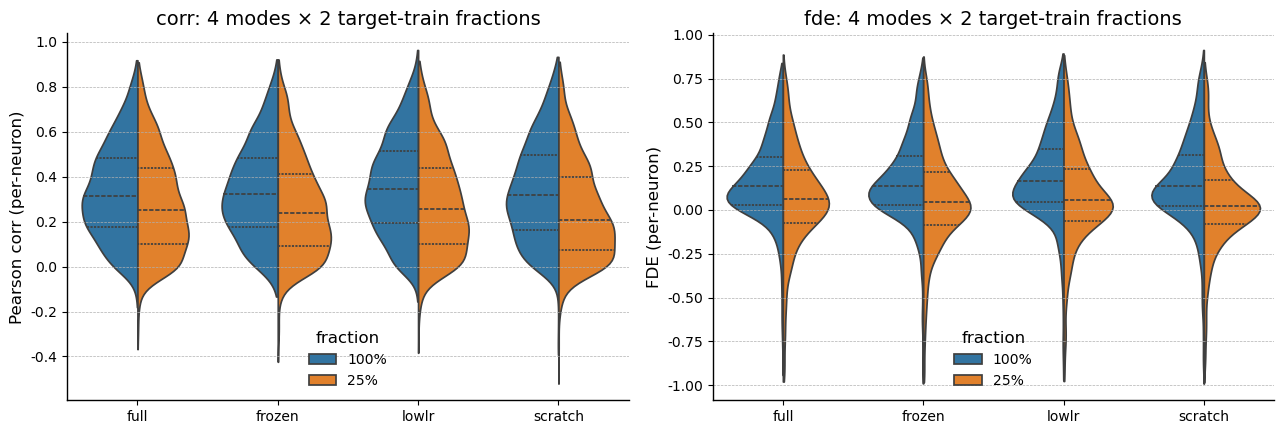

In [25]:
df_2x4_path = os.path.join(TWOXFOUR_DIR, 'results_2x4.pkl')
if os.path.exists(df_2x4_path):
    df_2x4 = pd.read_pickle(df_2x4_path)
    mode_order = list(MODES_2X4)
    fr_order = ['100%', '25%']

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric, ylabel in zip(
        axes, ('corr', 'fde'),
        ('Pearson corr (per-neuron)', 'FDE (per-neuron)'),
    ):
        sub = crop_for_plot(df_2x4, metric).copy()
        sub['fraction'] = sub['fraction_pct'].astype(int).astype(str) + '%'
        sns.violinplot(data=sub, x='mode', y=metric, hue='fraction',
                       order=mode_order, hue_order=fr_order,
                       split=True, inner='quartile', ax=ax, cut=0)
        ax.set_xlabel(''); ax.set_ylabel(ylabel)
        ax.set_title(f'{metric}: 4 modes \u00d7 2 target-train fractions')
    plt.tight_layout()

    rows = []
    for fr_pct, sub in df_2x4.groupby('fraction_pct'):
        for metric in ('fde', 'corr'):
            src = crop_for_plot(sub, metric)
            piv = src.pivot_table(
                index=['target_session', 'neuron_idx'],
                columns='mode', values=metric,
            )
            for a, b in [('full','frozen'), ('full','lowlr'), ('full','scratch'),
                         ('lowlr','frozen'), ('lowlr','scratch'), ('frozen','scratch')]:
                if a not in piv.columns or b not in piv.columns:
                    continue
                d = (piv[a] - piv[b]).dropna()
                if len(d) < 1:
                    continue
                try:
                    w = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                    wp, wW = float(w.pvalue), float(w.statistic)
                except ValueError:
                    wp, wW = np.nan, np.nan
                rows.append(dict(
                    fraction_pct=int(fr_pct), metric=metric, contrast=f'{a} \u2212 {b}',
                    n=int(len(d)), median=float(d.median()), mean=float(d.mean()),
                    frac_a_better=float((d > 0).mean()),
                    wilcoxon_W=wW, wilcoxon_p_two=wp,
                ))
    print('Paired per-neuron contrasts (Wilcoxon two-sided):')
    display(pd.DataFrame(rows).round(4))
else:
    print(f'No results yet at {df_2x4_path}.')